In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
X, y = data.data, data.target          # X: (569, 30), y: (569,) with values 0 or 1

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# standardize using TRAIN statistics only
mean, std = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print(X_train.shape, X_test.shape, y_train.mean())

(455, 30) (114, 30) 0.6285714285714286


In [1]:
import numpy as np

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [5]:
def predict_prob(X, w, b):
    return sigmoid(X @ w + b)

In [6]:
def loss(p, y):
    eps = 1e-12
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1-p))

In [9]:
def gradients(X, y, w, b):
    n = len(y)
    p = predict_prob(X, w, b)

    error = p - y
    dw = 1 / n * (X.T @ error)
    db = 1 / n * np.sum(error)

    return dw, db


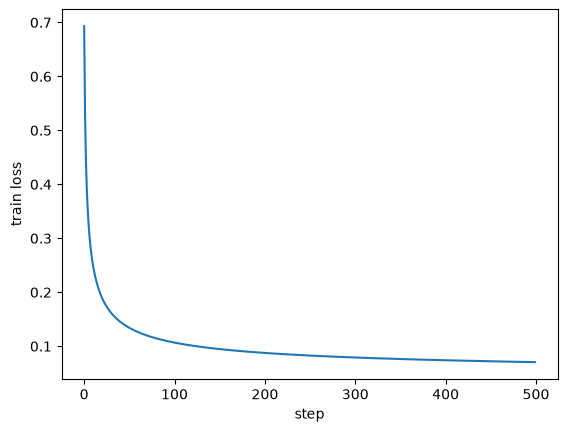

final train loss: 0.07048661857923608


In [11]:
w = np.zeros(X_train.shape[1])
b = 0.0

lr = 0.1
losses = []

for step in range(500):
    p = predict_prob(X_train, w, b)
    losses.append(loss(p, y_train))

    dw, db = gradients(X_train, y_train, w, b)
    w -= lr * dw
    b -= lr * db

plt.plot(losses)
plt.xlabel("step"); plt.ylabel("train loss"); plt.show()
print("final train loss:", losses[-1])

In [12]:
def predict_label(X, w, b):
    return (predict_prob(X, w, b) >= 0.5).astype(int)

train_acc = np.mean(predict_label(X_train, w, b) == y_train)
test_acc = np.mean(predict_label(X_test, w, b) == y_test)
print(f"train accuracy: {train_acc:.3f}")
print(f"test accuracy:  {test_acc:.3f}")

train accuracy: 0.987
test accuracy:  0.982


In [15]:
def numerical_gradients(X, y, w, b, eps=1e-5):
    dw_num = np.zeros_like(w)

    for i in range(len(w)):
        w_plus, w_minus = w.copy(), w.copy()
        w_plus[i] += eps
        w_minus[i] -= eps
        dw_num[i] = (loss(predict_prob(X, w_plus, b), y) - loss(predict_prob(X, w_minus, b), y)) / (2 * eps)

    db_num = (loss(predict_prob(X, w, b + eps), y) - loss(predict_prob(X, w, b - eps), y)) / (2 * eps)

    return dw_num, db_num

# test at a generic point, not at zero
rng = np.random.default_rng(0)
w_test = rng.normal(0, 0.1, size=30)
b_test = 0.3

dw, db = gradients(X_train, y_train, w_test, b_test)
dw_num, db_num = numerical_gradients(X_train, y_train, w_test, b_test)

print("max diff in dw:", np.abs(dw - dw_num).max())
print("diff in db:    ", abs(db - db_num))

max diff in dw: 1.6304659011812106e-11
diff in db:     1.0968864705418468e-12


In [16]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(penalty=None, max_iter=5000)
clf.fit(X_train, y_train)

print("sklearn train acc:", clf.score(X_train, y_train))
print("sklearn test acc: ", clf.score(X_test, y_test))
print("my test acc:      ", np.mean(predict_label(X_test, w, b) == y_test))

print("\nfirst 5 weights")
print("mine:   ", w[:5])
print("sklearn:", clf.coef_[0][:5])
print("bias  mine:", b, " sklearn:", clf.intercept_[0])

sklearn train acc: 1.0
sklearn test acc:  0.9385964912280702
my test acc:       0.9824561403508771

first 5 weights
mine:    [-0.51200811 -0.59461119 -0.49774814 -0.53205989 -0.19749424]
sklearn: [  9.43309636 -16.98638813  40.02092582  10.89014962   5.03344322]
bias  mine: 0.5377891208454495  sklearn: -63.53260018766379


/Users/mdadnanansari/ADNAN.prog/AI-ML-DL-NN/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


max |dw| at sklearn's solution: 4.046405006443619e-05
|db| at sklearn's solution:     2.2051316199542945e-05


/var/folders/ld/6p0md5qj4gldkr_4qtdlh5h00000gn/T/ipykernel_16495/3196251242.py:2: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


In [19]:
clf2 = LogisticRegression(max_iter=5000)
clf2.fit(X_train, y_train)
print("sklearn (L2) test acc:", clf2.score(X_test, y_test))
print("sklearn (L2) first 5 weights:", clf2.coef_[0][:5])

sklearn (L2) test acc: 0.9736842105263158
sklearn (L2) first 5 weights: [-0.43190368 -0.38732553 -0.39343248 -0.46521006 -0.07166728]
